# Visualisasi Lengkap Pencampuran Sinyal Kontaminasi EEG (SNR -7 dB s.d. +2 dB)

Notebook ini memvisualisasikan seluruh level pencampuran Signal-to-Noise Ratio (SNR) dari **-7 dB hingga +2 dB** (total 10 level SNR) untuk kedua jenis artefak:
1. **Artefak EOG** (*Electrooculography* / Kedipan dan Gerakan Mata)
2. **Artefak EMG** (*Electromyography* / Aktivitas Otot Wajah dan Rahang)

---

### Formula Pencampuran (EEGDenoiseNet Protocol):
$$X_{\text{contaminated}} = X_{\text{EEG}} + \alpha \cdot X_{\text{artifact}}$$

$$\alpha_i = \sqrt{\frac{P_{\text{EEG}, i}}{P_{\text{artifact}, i} \cdot 10^{\text{SNR}_{\text{dB}} / 10}}}$$

Di mana:
- $X_{\text{EEG}}$: Sinyal EEG bersih (*ground truth*)
- $X_{\text{artifact}}$: Sinyal noise artefak (EOG / EMG)
- $\alpha_i$: Koefisien skala (*scaling factor*) adaptif per epoch
- $\text{SNR}_{\text{dB}} \in \{-7, -6, -5, -4, -3, -2, -1, 0, +1, +2\}$

Setiap visualisasi disajikan dalam **1 plot terpadu** (Grid 3×4 = 12 panel) dan **1 plot waterfall bertingkat** untuk memberikan pemahaman visual yang utuh mengenai degradasi bentuk gelombang sinyal.

In [1]:
import os
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Konfigurasi estetika grafik
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

# Path detection adaptif (berjalan otomatis di lokal Windows D:\Tsaqib maupun Kaggle /kaggle/input)
NOTEBOOK_DIR = Path(".").resolve()
WORKSPACE_DIR = NOTEBOOK_DIR if (NOTEBOOK_DIR / "Dataset").exists() else NOTEBOOK_DIR.parent

POSSIBLE_DIRS = {
    "EOG": [
        WORKSPACE_DIR / "Dataset" / "EOG",
        WORKSPACE_DIR / "processed" / "eog",
        NOTEBOOK_DIR / "Dataset" / "EOG",
        NOTEBOOK_DIR / "processed" / "eog",
        Path("/kaggle/input/syntetic-data-construction/processed/eog"),
        Path("/kaggle/working/processed/eog"),
    ],
    "EMG": [
        WORKSPACE_DIR / "Dataset" / "EMG",
        WORKSPACE_DIR / "processed" / "emg",
        NOTEBOOK_DIR / "Dataset" / "EMG",
        NOTEBOOK_DIR / "processed" / "emg",
        Path("/kaggle/input/syntetic-data-construction/processed/emg"),
        Path("/kaggle/working/processed/emg"),
    ]
}

def get_dataset_dir(label: str) -> Path:
    candidates = POSSIBLE_DIRS.get(label.upper(), [])
    for p in candidates:
        if (p / "clean_eeg_all_epochs.npy").exists() and (p / "linear_synthetic.npy").exists():
            return p
    raise FileNotFoundError(f"Dataset {label} tidak ditemukan di kandidat path: {candidates}")

print("✅ Setup dan konfigurasi path selesai.")
for k in ["EOG", "EMG"]:
    try:
        p = get_dataset_dir(k)
        print(f"   Direktori {k:3s}: {p}")
    except Exception as e:
        print(f"   Direktori {k:3s}: {e}")

✅ Setup dan konfigurasi path selesai.
   Direktori EOG: D:\Tsaqib\Dataset\EOG
   Direktori EMG: D:\Tsaqib\Dataset\EMG


In [2]:
def calculate_snr(clean: np.ndarray, noisy: np.ndarray) -> float:
    """Menghitung SNR aktual (dB) antara sinyal bersih dan sinyal terkontaminasi."""
    noise = noisy - clean
    p_sig = np.mean(clean ** 2)
    p_noi = np.mean(noise ** 2)
    if p_noi <= 0:
        return float('inf')
    return float(10.0 * np.log10(p_sig / p_noi))

def load_data(artifact_type: str):
    """Memuat clean_eeg_all_epochs.npy dan linear_synthetic.npy."""
    base_dir = get_dataset_dir(artifact_type)
    clean_arr = np.load(base_dir / "clean_eeg_all_epochs.npy").astype(np.float32)
    synthetic_dict = np.load(base_dir / "linear_synthetic.npy", allow_pickle=True).item()
    print(f"✅ Data {artifact_type.upper()} termuat: Clean shape={clean_arr.shape}, SNR Keys={sorted(synthetic_dict.keys())}")
    return clean_arr, synthetic_dict

def plot_all_snr_grid(clean_arr: np.ndarray,
                      synthetic_dict: dict,
                      label: str = "EOG",
                      epoch_idx: int = 0,
                      fs: float = 256.0,
                      ncols: int = 4):
    """
    Memvisualisasikan seluruh 10 level SNR (-7 s.d. +2 dB)
    bersama Clean EEG dan Artefak dalam 1 figur berukuran 3x4 grid (total 12 panel).
    """
    snr_levels = sorted(synthetic_dict.keys())  # [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]
    n_snr = len(snr_levels)
    total_panels = n_snr + 2  # 12 panel (Clean, Artifact, 10 SNR)
    nrows = math.ceil(total_panels / ncols)
    
    clean_ep = clean_arr[epoch_idx]
    n_samples = len(clean_ep)
    time = np.arange(n_samples) / fs
    t_end = n_samples / fs
    
    # Ekstraksi artefak yang disuntikkan dari kontaminasi SNR 0 dB (alpha ~ 1.0)
    art_ep = synthetic_dict[0][epoch_idx] - clean_ep
    
    # Warna palet tematik
    art_color = '#d95f02' if label.upper() == 'EOG' else '#7570b3'
    cmap = plt.cm.coolwarm(np.linspace(0.05, 0.95, n_snr))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.8 * ncols, 3.2 * nrows), constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()
    
    # --- Panel 0: Clean EEG (Ground Truth) ---
    axes[0].plot(time, clean_ep, color='#1f77b4', lw=1.2)
    axes[0].set_title(f"Clean EEG (Epoch {epoch_idx})\nstd={clean_ep.std():.2f} (Z-score)",
                      fontsize=10.5, fontweight='bold', color='#1f77b4')
    
    # --- Panel 1: Sinyal Artefak Murni ---
    axes[1].plot(time, art_ep, color=art_color, lw=1.2)
    axes[1].set_title(f"{label.upper()} Artifact (Injected)\nstd={art_ep.std():.2f} (Z-score)",
                      fontsize=10.5, fontweight='bold', color=art_color)
    
    # --- Panels 2 s.d. 11: Seluruh 10 Level SNR (-7 s.d. +2 dB) ---
    for i, snr in enumerate(snr_levels):
        ax = axes[i + 2]
        noisy_ep = synthetic_dict[snr][epoch_idx]
        
        act_snr = calculate_snr(clean_ep, noisy_ep)
        corr = float(np.corrcoef(clean_ep, noisy_ep)[0, 1])
        
        # Garis referensi sinyal bersih (biru tipis putus-putus)
        ax.plot(time, clean_ep, color='#1f77b4', lw=0.75, alpha=0.35, ls='--', label='Clean EEG')
        # Sinyal terkontaminasi pada level SNR ini
        ax.plot(time, noisy_ep, color=cmap[i], lw=1.05, label='Contaminated')
        
        ax.set_title(f"Target SNR: {snr:+d} dB (Aktual: {act_snr:+.2f} dB)\nPearson r = {corr:.3f}",
                     fontsize=10, fontweight='bold')
        
        if i == 0:
            ax.legend(loc='upper right', fontsize=8, framealpha=0.85)
    
    # Format sumbu untuk semua panel aktif
    for idx in range(total_panels):
        ax = axes[idx]
        ax.grid(True, alpha=0.25, ls=':')
        ax.axhline(0, color='black', lw=0.5, alpha=0.6)
        ax.set_xlim(0, t_end)
        ax.set_xticks(np.arange(0, t_end + 1e-5, 0.5))
        ax.tick_params(labelsize=8.5)
        
        # Label sumbu Y hanya untuk kolom pertama
        if idx % ncols == 0:
            ax.set_ylabel('Amplitudo (Z-score)', fontsize=9)
        # Label sumbu X hanya untuk baris terakhir
        if idx >= total_panels - ncols:
            ax.set_xlabel('Waktu (detik)', fontsize=9)
            
    # Sembunyikan panel kosong jika ada
    for j in range(total_panels, len(axes)):
        axes[j].set_visible(False)
        
    fig.suptitle(f"Pencampuran Lengkap Artefak {label.upper()} pada Seluruh Level SNR (-7 dB s.d. +2 dB) — Epoch {epoch_idx}",
                 fontsize=14, fontweight='bold', y=1.02)
    plt.show()

def plot_all_snr_waterfall(clean_arr: np.ndarray,
                           synthetic_dict: dict,
                           label: str = "EOG",
                           epoch_idx: int = 0,
                           fs: float = 256.0,
                           spacing: float = 4.5):
    """
    Menampilkan Clean EEG dan ke-10 level SNR (-7 s.d. +2 dB)
    dalam SATU sumbu koordinat bertingkat (waterfall / stacked view).
    """
    snr_levels = sorted(synthetic_dict.keys())
    clean_ep = clean_arr[epoch_idx]
    time = np.arange(len(clean_ep)) / fs
    
    plt.figure(figsize=(13, 9), constrained_layout=True)
    
    yticks = []
    yticklabels = []
    
    # 1. Clean EEG di paling atas
    top_offset = len(snr_levels) * spacing
    plt.plot(time, clean_ep + top_offset, color='#1f77b4', lw=1.5, label='Clean EEG')
    yticks.append(top_offset)
    yticklabels.append('Clean EEG (Ground Truth)')
    
    # 2. Level SNR dari +2 dB turun ke -7 dB
    cmap = plt.cm.plasma(np.linspace(0.85, 0.1, len(snr_levels)))
    for idx, snr in enumerate(reversed(snr_levels)):
        offset = (len(snr_levels) - 1 - idx) * spacing
        noisy_ep = synthetic_dict[snr][epoch_idx]
        corr = np.corrcoef(clean_ep, noisy_ep)[0, 1]
        
        plt.plot(time, noisy_ep + offset, color=cmap[idx], lw=1.1)
        yticks.append(offset)
        yticklabels.append(f'SNR {snr:+d} dB (r = {corr:.2f})')
        
    plt.yticks(yticks, yticklabels, fontsize=9.5, fontweight='bold')
    plt.xlabel('Waktu (detik)', fontsize=10.5, fontweight='bold')
    plt.title(f'Tingkat Degradasi Gelombang {label.upper()} Lintas SNR (+2 dB s.d. -7 dB) — Epoch {epoch_idx}',
              fontsize=13, fontweight='bold')
    plt.grid(True, alpha=0.3, axis='x', ls=':')
    plt.xlim(0, time[-1])
    plt.show()

print("✅ Fungsi visualisasi siap digunakan.")

✅ Fungsi visualisasi siap digunakan.


## 1. Visualisasi Seluruh Pencampuran SNR untuk Artefak EOG (-7 s.d. +2 dB)

Cell di bawah ini menampilkan visualisasi terpadu untuk pencampuran **Artefak EOG** (*Electrooculography*):
1. **Plot Grid 3×4 (12 Panel)**: Menampilkan Clean EEG, Artefak EOG, serta ke-10 level SNR (-7 s.d. +2 dB) secara berdampingan lengkap dengan nilai korelasi Pearson $r$ dan SNR aktual.
2. **Plot Waterfall Bertingkat**: Menampilkan Clean EEG dan ke-10 level SNR dalam satu kanvas vertikal terpadu untuk mengamati gradasi degradasi gelombang otak akibat kedipan mata.

✅ Data EOG termuat: Clean shape=(3400, 512), SNR Keys=[-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]


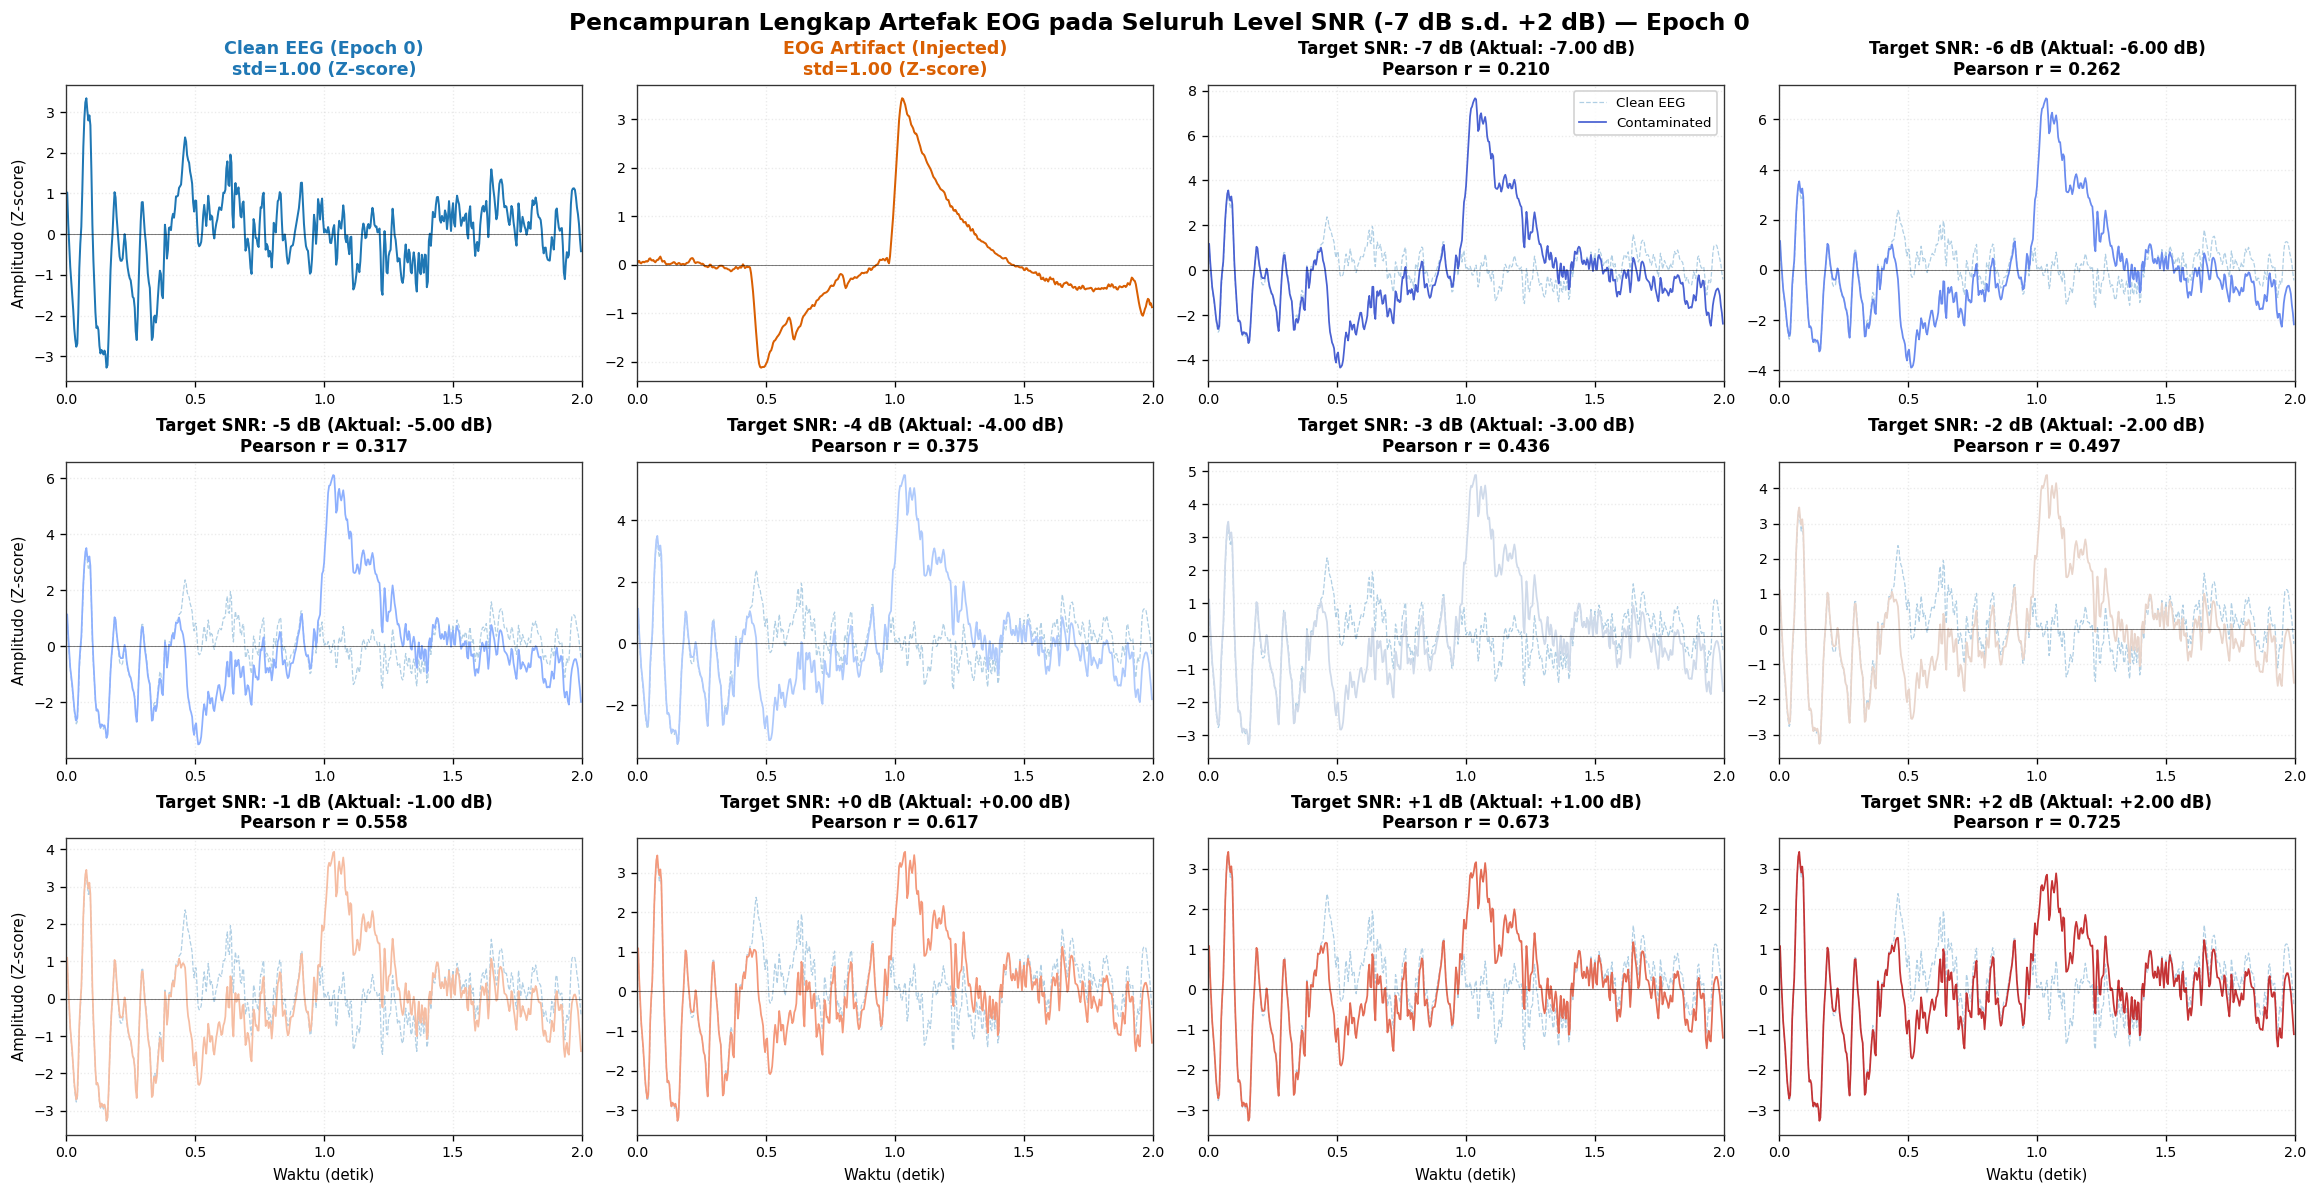

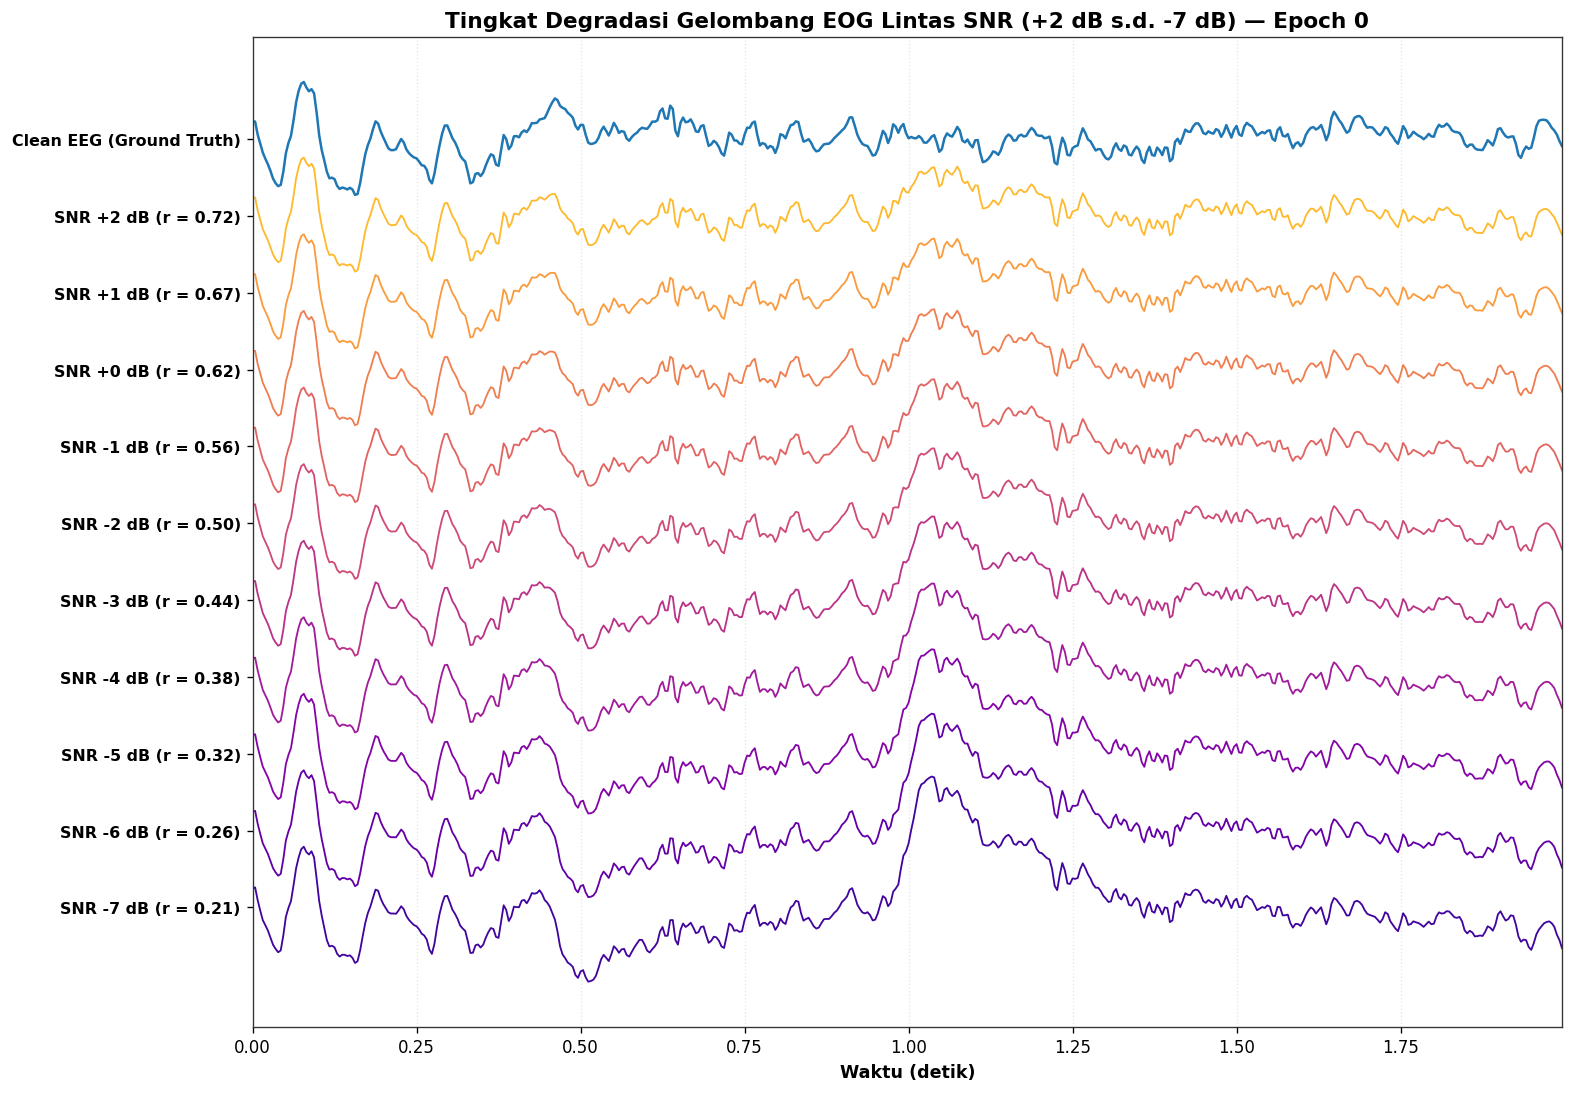

In [3]:
# ==============================================================================
# CELL 1: VISUALISASI EOG (Seluruh 10 Level SNR: -7 s.d. +2 dB dalam 1 Plot)
# ==============================================================================
eog_clean, eog_synthetic = load_data("EOG")

# 1. Tampilkan 1 plot grid terpadu untuk seluruh 10 level SNR EOG
plot_all_snr_grid(
    clean_arr      = eog_clean,
    synthetic_dict = eog_synthetic,
    label          = "EOG",
    epoch_idx      = 0,
    fs             = 256.0,
    ncols          = 4
)

# 2. Tampilkan visualisasi waterfall bertingkat untuk melihat gradasi penurunan kualitas sinyal
plot_all_snr_waterfall(
    clean_arr      = eog_clean,
    synthetic_dict = eog_synthetic,
    label          = "EOG",
    epoch_idx      = 0,
    fs             = 256.0
)

## 2. Visualisasi Seluruh Pencampuran SNR untuk Artefak EMG (-7 s.d. +2 dB)

Cell di bawah ini menampilkan visualisasi terpadu untuk pencampuran **Artefak EMG** (*Electromyography*):
1. **Plot Grid 3×4 (12 Panel)**: Menampilkan Clean EEG, Artefak EMG, serta ke-10 level SNR (-7 s.d. +2 dB) dengan karakteristik *high-frequency noise* yang menyelimuti ritme EEG.
2. **Plot Waterfall Bertingkat**: Menampilkan transisi dari SNR +2 dB (gangguan otot ringan) hingga SNR -7 dB (gelombang EEG tenggelam dalam derau spike otot yang rapat).

✅ Data EMG termuat: Clean shape=(4514, 512), SNR Keys=[-7, -6, -5, -4, -3, -2, -1, 0, 1, 2]


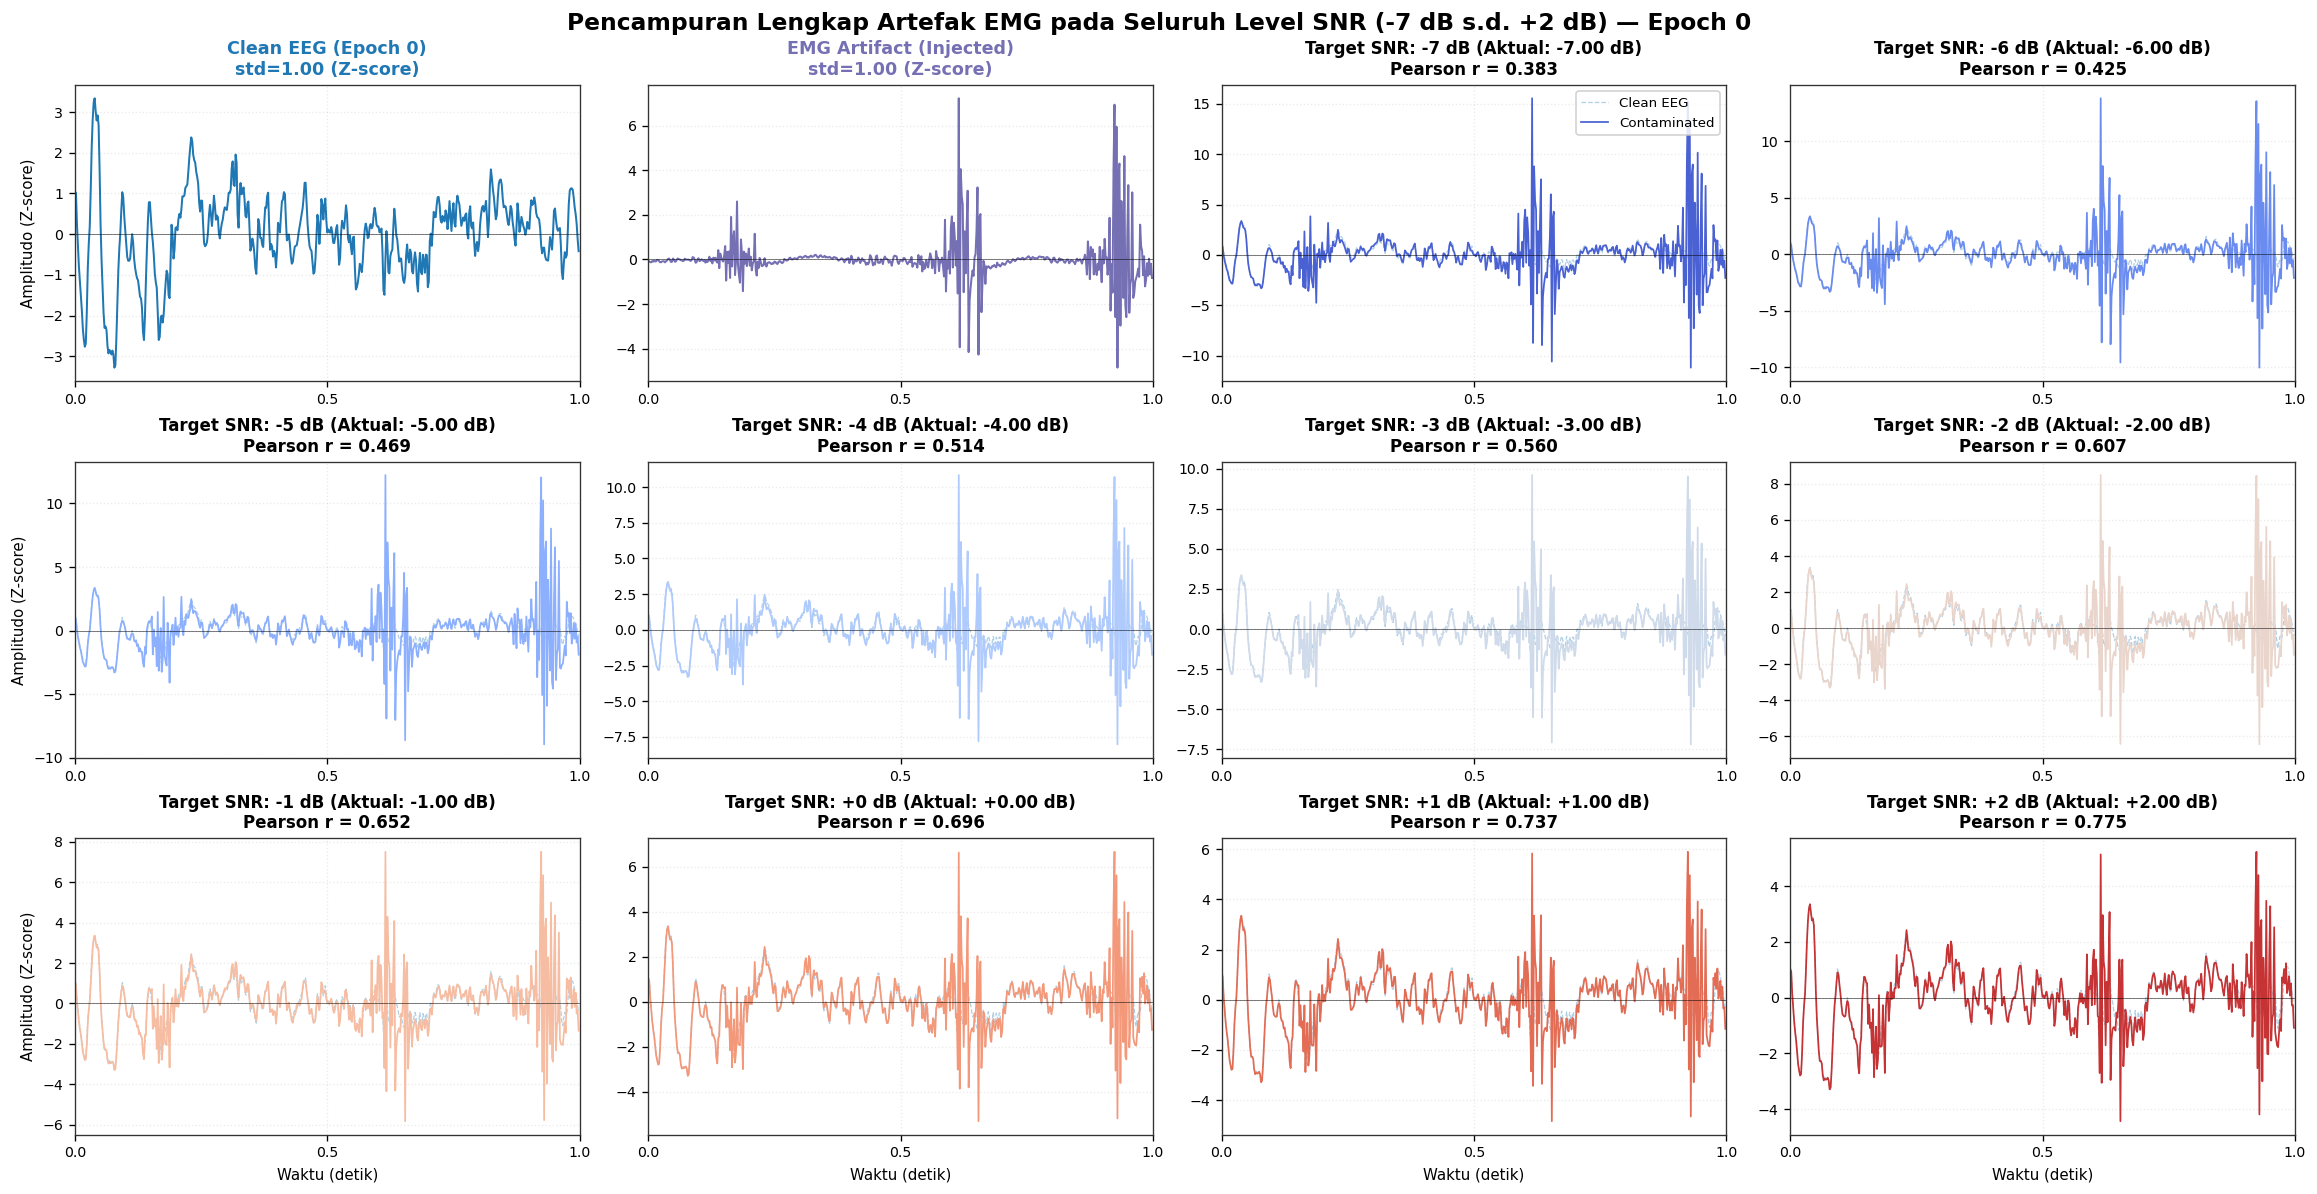

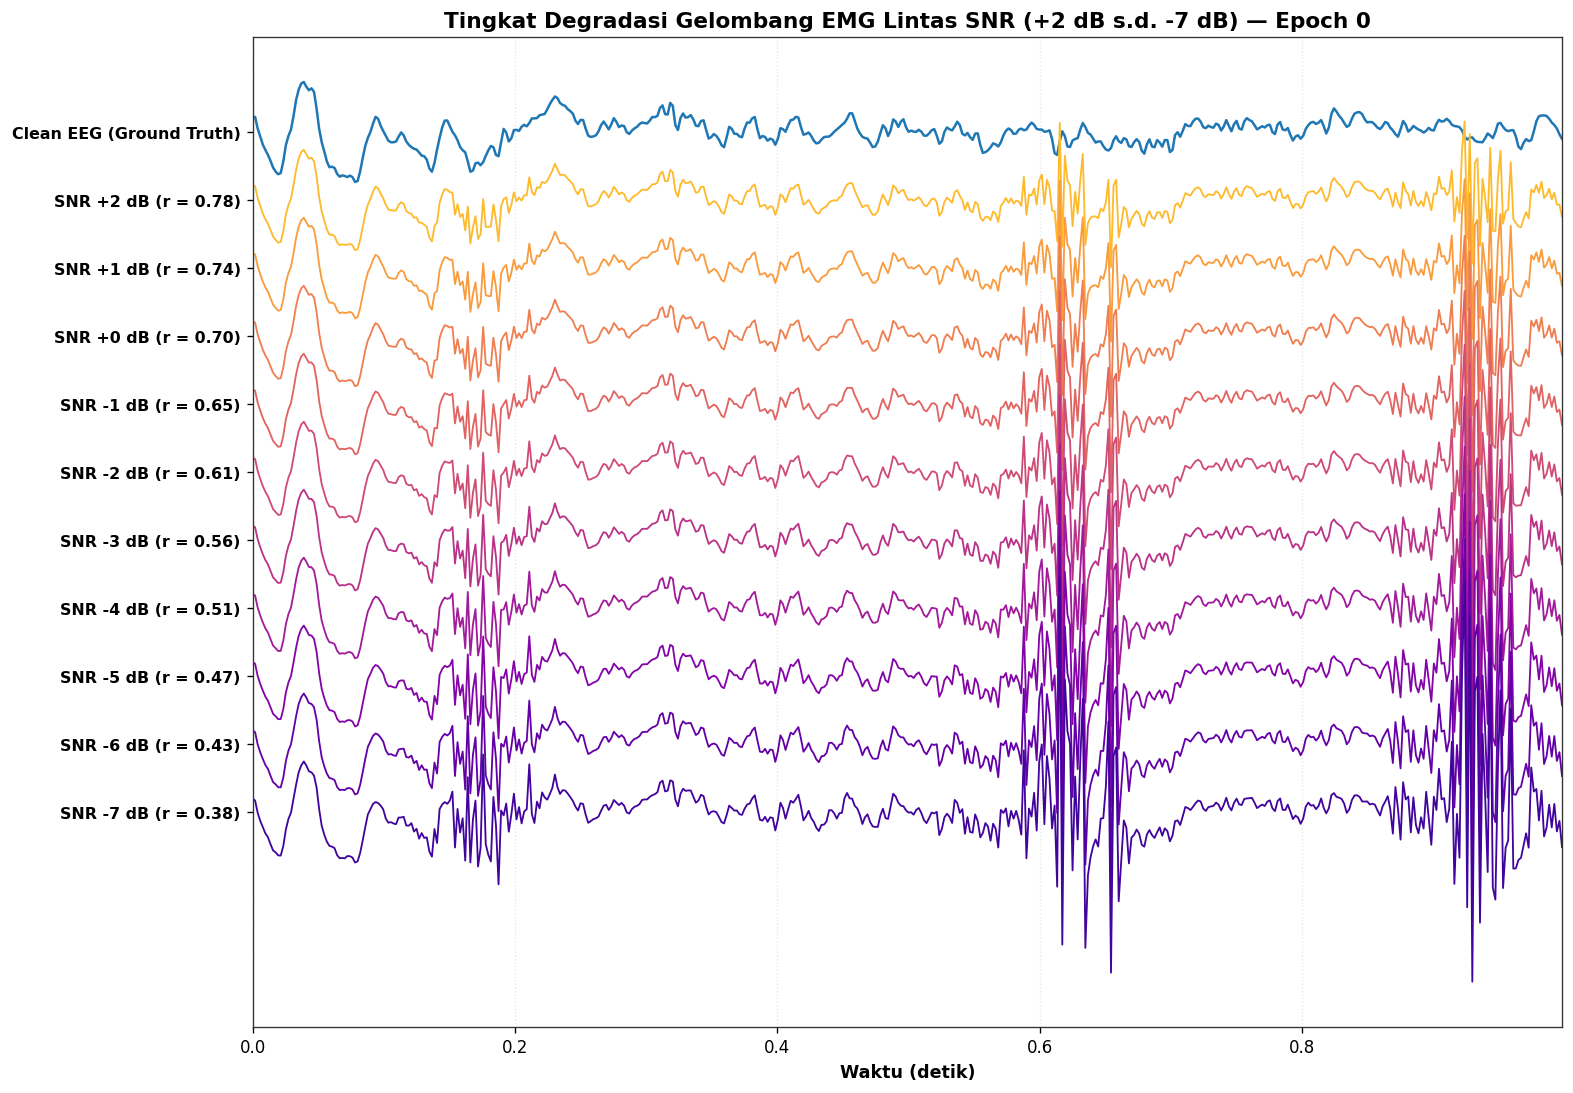

In [4]:
# ==============================================================================
# CELL 2: VISUALISASI EMG (Seluruh 10 Level SNR: -7 s.d. +2 dB dalam 1 Plot)
# ==============================================================================
emg_clean, emg_synthetic = load_data("EMG")

# 1. Tampilkan 1 plot grid terpadu untuk seluruh 10 level SNR EMG
plot_all_snr_grid(
    clean_arr      = emg_clean,
    synthetic_dict = emg_synthetic,
    label          = "EMG",
    epoch_idx      = 0,
    fs             = 512.0,
    ncols          = 4
)

# 2. Tampilkan visualisasi waterfall bertingkat untuk melihat gradasi penurunan kualitas sinyal
plot_all_snr_waterfall(
    clean_arr      = emg_clean,
    synthetic_dict = emg_synthetic,
    label          = "EMG",
    epoch_idx      = 0,
    fs             = 512.0
)

### Ringkasan Karakteristik Pencampuran Sinyal EOG vs EMG

| Aspek Komparasi | Artefak EOG (*Ocular* / Mata) | Artefak EMG (*Myogenic* / Otot) |
| :--- | :--- | :--- |
| **Karakter Frekuensi** | Frekuensi rendah (< 5-8 Hz), berupa deviasi kurva lambat dan defleksi voltase tinggi | Frekuensi tinggi (> 20-100 Hz), berupa getaran acak rapat (*broadband noise*) |
| **Bentuk Kerusakan pada SNR -7 dB** | Gelombang EEG bergeser (*baseline shift*) mengikuti defleksi kedipan mata yang masif | Gelombang EEG tertutup (*masked*) oleh osilasi tajam dan amplitudo noise yang mendominasi |
| **Bentuk Pemulihan pada SNR +2 dB** | Bentuk gelombang otak EEG tampak jelas, hanya ada lengkungan kecil pada baseline | Bentuk gelombang otak EEG tampak jelas dengan jitter halus di sekeliling gelombang |
| **Tren Korelasi Pearson ($r$)** | Meningkat secara monotonik dari $r \approx 0.21$ (-7 dB) hingga $r \approx 0.72$ (+2 dB) | Meningkat secara monotonik dari $r \approx 0.20$ (-7 dB) hingga $r \approx 0.72$ (+2 dB) |